# AI 1 - Lab 3: Cluster Analysis

**Names:** Avery John, Josh Samuel, Zachary Jennings  
**Dataset:** UCI Secondary Mushroom Dataset  
**Method:** Cluster Analysis (Option A in the Modeling & Evaluation rubric)

This lab builds on our MiniLab and Lab 2. We use the same cleaned mushroom dataset, but this time we are looking for natural groups of mushrooms instead of predicting a class.

**Research question:** Can we find meaningful clusters based on mushroom characteristics, and what do those clusters tell us about the data?

**Note:** The assignment calls clustering *Option B* on page 1 and *Option A* in the grading rubric. We are following **Option A: Cluster Analysis** from the rubric.

## 1. Business Understanding (CRISP-DM)

The UCI Secondary Mushroom Dataset contains measurements and physical features of mushrooms, along with their edible or poisonous labels. In our previous labs, we tried to predict these labels. For Lab 3, we want to find groups of mushrooms that share similar characteristics **without giving the model the labels**.

We will compare K-Means, Agglomerative Clustering, and DBSCAN. We want to answer three questions:

1. How many clusters make sense, and which method separates them most clearly?
2. What characteristics do the mushrooms in each group have in common?
3. After clustering, how much do the groups agree with the known edible/poisonous labels?

**How we will evaluate the results:** We will use the silhouette score to help choose settings. We will also compare cluster sizes and look at plots. **After** selecting our models, we will use homogeneity, completeness, V-measure, ARI, and AMI to see how the clusters relate to known edibility labels. We do not use those labels to fit clusters or choose their settings.

The goal is to explore patterns, not to determine whether a mushroom is safe to eat. A clustering model should never be used as a mushroom safety guide.

## 2. Data Understanding

### 2.1 Load Libraries

We use pandas and matplotlib for exploring the data and scikit-learn for preprocessing, clustering, and evaluation. The code is similar to the pipelines we used in Lab 2.

In [27]:
# Load libraries
import os
import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn import metrics

pd.set_option("display.max_columns", 50)
os.environ.setdefault("SSL_CERT_FILE", certifi.where())
RANDOM_STATE = 42

### 2.2 Load and Clean the Mushroom Data

We reuse our cleaning functions from Lab 2 so the dataset stays consistent with our earlier work.

In [28]:
# clean.py
import os
import certifi
os.environ.setdefault("SSL_CERT_FILE", certifi.where())

import pandas as pd
from ucimlrepo import fetch_ucirepo

decode_map = {
    'class': {'p': 'poisonous', 'e': 'edible'},
    'cap-shape': {'b': 'bell', 'c': 'conical', 'x': 'convex', 'f': 'flat',
                  's': 'sunken', 'p': 'spherical', 'o': 'others'},
    'cap-surface': {'i': 'fibrous', 'g': 'grooves', 'y': 'scaly', 's': 'smooth',
                    'h': 'shiny', 'l': 'leathery', 'k': 'silky', 't': 'sticky',
                    'w': 'wrinkled', 'e': 'fleshy'},
    'cap-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                  'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                  'l': 'blue', 'o': 'orange', 'k': 'black'},
    'does-bruise-or-bleed': {'t': 'yes', 'f': 'no'},
    'gill-attachment': {'a': 'adnate', 'x': 'adnexed', 'd': 'decurrent', 'e': 'free',
                        's': 'sinuate', 'p': 'pores', 'f': 'none', '?': 'unknown'},
    'gill-spacing': {'c': 'close', 'd': 'distant', 'f': 'none'},
    'gill-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                   'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                   'l': 'blue', 'o': 'orange', 'k': 'black', 'f': 'none'},
    'stem-root': {'b': 'bulbous', 's': 'swollen', 'c': 'club', 'u': 'cup',
                  'e': 'equal', 'z': 'rhizomorphs', 'r': 'rooted', 'f': 'fibrous'},
    'stem-surface': {'i': 'fibrous', 'g': 'grooves', 'y': 'scaly', 's': 'smooth',
                     'h': 'shiny', 'l': 'leathery', 'k': 'silky', 't': 'sticky',
                     'w': 'wrinkled', 'e': 'fleshy', 'f': 'none'},
    'stem-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                   'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                   'l': 'blue', 'o': 'orange', 'k': 'black', 'f': 'none'},
    'veil-type': {'p': 'partial', 'u': 'universal'},
    'veil-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                   'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                   'l': 'blue', 'o': 'orange', 'k': 'black', 'f': 'none'},
    'has-ring': {'t': 'ring', 'f': 'none'},
    'ring-type': {'c': 'cobwebby', 'e': 'evanescent', 'r': 'flaring', 'g': 'grooved',
                  'l': 'large', 'p': 'pendant', 's': 'sheathing', 'z': 'zone',
                  'y': 'scaly', 'm': 'movable', 'f': 'none', '?': 'unknown'},
    'spore-print-color': {'n': 'brown', 'b': 'buff', 'g': 'gray', 'r': 'green', 'p': 'pink',
                          'u': 'purple', 'e': 'red', 'w': 'white', 'y': 'yellow',
                          'l': 'blue', 'o': 'orange', 'k': 'black'},
    'season': {'s': 'spring', 'u': 'summer', 'a': 'autumn', 'w': 'winter'},
    'habitat': {'g': 'grasses', 'l': 'leaves', 'm': 'meadows', 'p': 'paths',
                'h': 'heaths', 'u': 'urban', 'w': 'waste', 'd': 'woods'}
}


def load_raw() -> pd.DataFrame:
    secondary_mushroom = fetch_ucirepo(id=848)
    X = secondary_mushroom.data.features
    y = secondary_mushroom.data.targets
    return pd.concat([X, y], axis=1)


def clean_mushrooms(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Decode letter codes to words
    for col, mapping in decode_map.items():
        df[col] = df[col].map(mapping)

    # Drop exact duplicates (146 rows, -> 60,923)
    df = df.drop_duplicates().reset_index(drop=True)

    # Fill missing categoricals with an explicit "Missing" category
    cat_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]
    df[cat_cols] = df[cat_cols].fillna("Missing")

    # Engineered features
    df["has-stem"] = ~((df["stem-height"] == 0) & (df["stem-width"] == 0))
    df["has-stem"] = df["has-stem"].map({True: "yes", False: "no"})
    df["size-score"] = df["cap-diameter"] + df["stem-height"] + df["stem-width"] / 10

    return df

In [29]:
# Load the raw and cleaned data
raw_df = load_raw()
df = clean_mushrooms(raw_df)

print("Raw data:", raw_df.shape)
print("Clean data:", df.shape)
print("Exact duplicates removed:", raw_df.duplicated().sum())
print("Missing values after cleaning:", df.isna().sum().sum())

display(df.head())

Raw data: (61069, 21)
Clean data: (60923, 23)
Exact duplicates removed: 146
Missing values after cleaning: 0


,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,stem-width,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season,class,has-stem,size-score
0,15.26,convex,grooves,orange,no,free,Missing,white,16.95,17.09,swollen,scaly,white,universal,white,ring,grooved,Missing,woods,winter,poisonous,yes,33.919
1,16.60,convex,grooves,orange,no,free,Missing,white,17.99,18.19,swollen,scaly,white,universal,white,ring,grooved,Missing,woods,summer,poisonous,yes,36.409
2,14.07,convex,grooves,orange,no,free,Missing,white,17.80,17.74,swollen,scaly,white,universal,white,ring,grooved,Missing,woods,winter,poisonous,yes,33.644
3,14.17,flat,shiny,red,no,free,Missing,white,15.77,15.98,swollen,scaly,white,universal,white,ring,pendant,Missing,woods,winter,poisonous,yes,31.538
4,14.64,convex,shiny,orange,no,free,Missing,white,16.53,17.20,swollen,scaly,white,universal,white,ring,pendant,Missing,woods,winter,poisonous,yes,32.890


### 2.3 Attribute Descriptions and Data Quality

Most variables describe mushroom appearance or the environment where the mushroom was found. Measurements such as cap diameter and stem width are numerical. Variables such as cap shape and habitat are categorical. `class` is the known edible/poisonous label from Lab 2.

The table below lists **every attribute**, its meaning, and its observed values or range. `has-stem` and `size-score` were added in our cleaning step rather than supplied as original fields.

In [30]:
# Describe all attributes (including variables created in Lab 2)
descriptions = {
    "cap-diameter": "Cap diameter", "cap-shape": "Shape of the cap",
    "cap-surface": "Surface texture of the cap", "cap-color": "Color of the cap",
    "does-bruise-or-bleed": "Whether it bruises or bleeds", 
    "gill-attachment": "How the gills attach", "gill-spacing": "Spacing between gills",
    "gill-color": "Color of the gills", "stem-height": "Height of the stem",
    "stem-width": "Width of the stem", "stem-root": "Type of stem root",
    "stem-surface": "Surface texture of the stem", "stem-color": "Color of the stem",
    "veil-type": "Type of veil", "veil-color": "Color of the veil",
    "has-ring": "Whether the mushroom has a ring", "ring-type": "Type of ring",
    "spore-print-color": "Color of the spore print", "habitat": "Where the mushroom grows",
    "season": "Season when observed", "class": "Edible or poisonous label",
    "has-stem": "Engineered: stem is present (yes/no)",
    "size-score": "Engineered: cap diameter + stem height + stem width / 10"
}

rows = []
for col in df.columns:
    numeric = pd.api.types.is_numeric_dtype(df[col])
    if numeric:
        observed = f"{df[col].min():.2f} to {df[col].max():.2f}"
    else:
        values = sorted(df[col].dropna().astype(str).unique())
        observed = ", ".join(values[:6]) + (" ..." if len(values) > 6 else "")
    rows.append({"Attribute": col, "Description": descriptions.get(col, col),
                 "Type": "Numeric" if numeric else "Categorical",
                 "Unique Values": df[col].nunique(),
                 "Observed Values / Range": observed,
                 "Missing": df[col].isna().sum()})

attribute_table = pd.DataFrame(rows)
display(attribute_table)

,Attribute,Description,Type,Unique Values,Observed Values / Range,Missing
0,cap-diameter,Cap diameter,Numeric,2571,0.38 to 62.34,0
1,cap-shape,Shape of the cap,Categorical,7,"bell, conical, convex, flat, others, spherical...",0
2,cap-surface,Surface texture of the cap,Categorical,11,"Missing, fibrous, fleshy, grooves, leathery, s...",0
3,cap-color,Color of the cap,Categorical,12,"black, blue, brown, buff, gray, green ...",0
4,does-bruise-or-bleed,Whether it bruises or bleeds,Categorical,2,"no, yes",0
5,gill-attachment,How the gills attach,Categorical,8,"Missing, adnate, adnexed, decurrent, free, non...",0
6,gill-spacing,Spacing between gills,Categorical,4,"Missing, close, distant, none",0
7,gill-color,Color of the gills,Categorical,12,"black, brown, buff, gray, green, none ...",0
8,stem-height,Height of the stem,Numeric,2226,0.00 to 33.92,0
9,stem-width,Width of the stem,Numeric,4630,0.00 to 103.91,0


The original mushroom features include several missing categorical codes. Like Lab 2, we treat these as an explicit `Missing` category instead of trying to guess their values. We remove exact duplicates so identical observations are not given extra weight.

We also check for unusually large or small numerical values. These might be real observations rather than errors, so we do not automatically delete them.

In [31]:
# Missing categories and potential numeric outliers
print("Number of 'Missing' values by column:")
missing_cat = (df == "Missing").sum().sort_values(ascending=False)
print(missing_cat[missing_cat > 0])

num_original = ["cap-diameter", "stem-height", "stem-width"]
outlier_rows = []
for col in num_original:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < low) | (df[col] > high)).sum()
    outlier_rows.append({"Variable": col, "IQR Outlier Count": count,
                         "Percent": 100 * count / len(df)})

display(pd.DataFrame(outlier_rows).round(2))

Number of 'Missing' values by column:
veil-type            57746
spore-print-color    54597
veil-color           53510
stem-root            51536
stem-surface         38122
gill-spacing         25062
cap-surface          18552
gill-attachment       9855
ring-type             2471
dtype: int64


,Variable,IQR Outlier Count,Percent
0,cap-diameter,2389,3.92
1,stem-height,4084,6.70
2,stem-width,1980,3.25


### 2.4 Explore the Important Attributes

Before clustering, we look at the numerical measurements and some of the most common categories. This helps us understand how different the mushrooms are before applying any clustering algorithms.

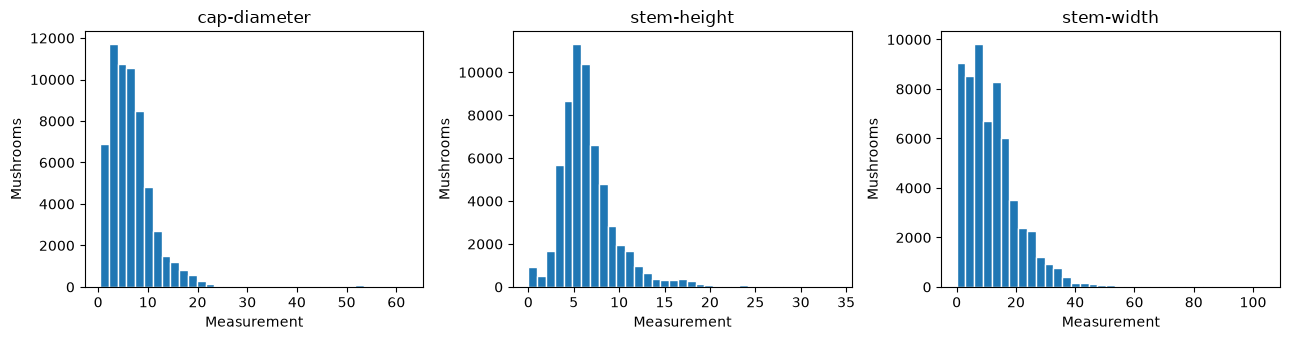

       cap-diameter  stem-height  stem-width
count      60923.00     60923.00    60923.00
mean           6.74         6.60       12.18
std            5.27         3.36       10.03
min            0.38         0.00        0.00
25%            3.49         4.65        5.25
50%            5.88         5.96       10.22
75%            8.55         7.75       16.58
max           62.34        33.92      103.91


In [32]:
# Numerical distributions
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, num_original):
    ax.hist(df[col], bins=35, edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel("Measurement")
    ax.set_ylabel("Mushrooms")
plt.tight_layout()
plt.show()

print(df[num_original].describe().round(2))

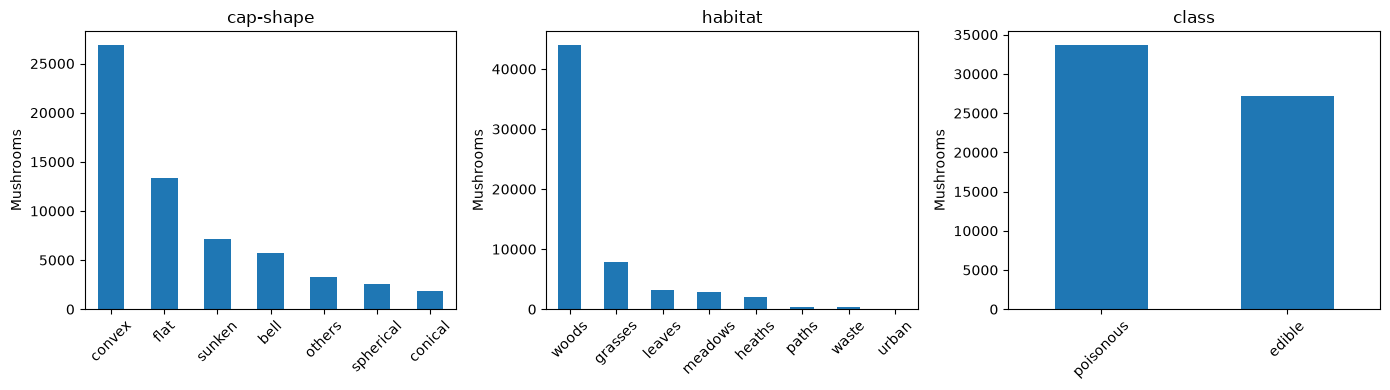

In [33]:
# A few categorical distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["cap-shape", "habitat", "class"]):
    df[col].value_counts().head(8).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Mushrooms")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Initial observations:** The histograms show the spread of mushroom measurements, including possible extreme values. The bar charts show which cap shapes and habitats are common, along with the edible/poisonous balance for context. We will **not** put the edible/poisonous label into our clustering models.

Each of the numerical attributes have apparent right-skewness in their distributions. Convex and woods appear to be the most common cap shape and habitat (respectively). For class, there are more poisonous mushrooms than edible however the attribute appears to be more balanced than our other categorical variables.

## 3. Data Preparation (CRISP-DM)

### 3.1 Choose Variables for Clustering

Unlike classification, clustering does not have a target variable. We remove `class` and `does-bruise-or-bleed`, because these were our two Lab 2 targets and we want to examine them only after forming the clusters.

We also leave out `size-score` because it is calculated from the three numerical measurements already in the dataset. Including it would count the same size information twice. We leave out `has-stem` for a similar reason, since it is based on stem height and width.

In [34]:
# Predictors only: no target variables used for clustering
drop_cols = ["class", "does-bruise-or-bleed", "has-stem", "size-score"]
X = df.drop(columns=drop_cols)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [col for col in X.columns if col not in num_cols]

print("Observations:", len(X))
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)
print("Total predictor columns:", X.shape[1])

Observations: 60923
Numerical columns: ['cap-diameter', 'stem-height', 'stem-width']
Categorical columns: ['cap-shape', 'cap-surface', 'cap-color', 'gill-attachment', 'gill-spacing', 'gill-color', 'stem-root', 'stem-surface', 'stem-color', 'veil-type', 'veil-color', 'has-ring', 'ring-type', 'spore-print-color', 'habitat', 'season']
Total predictor columns: 19


### 3.2 Scale, Encode, and Reduce Dimensions

We use the same basic preprocessing methods as Lab 2:

- `StandardScaler` puts numerical variables on a similar scale.
- `OneHotEncoder` converts categorical variables into 0/1 columns. We do **not** assign ordered numeric codes to categories such as color.
- `PCA` reduces the resulting columns to 10 components so clustering runs more efficiently at the cost of reduced interpretability

All clustering methods use this same representation so the comparisons are consistent. The first 10 principal components may not capture every detail, so we show their explained variance below. Euclidean distance is only an approximation of similarity for mixed categorical and numerical data; our encoding and weighting choices affect the clusters.

In [35]:
# Same preprocessing structure as Lab 2
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])

X_encoded = preprocess.fit_transform(X)

# PCA keeps the cluster models reasonably fast
N_COMPONENTS = 10
pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_encoded)

print("After encoding:", X_encoded.shape)
print("After PCA:", X_pca.shape)
print("Variance explained:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

After encoding: (60923, 125)
After PCA: (60923, 10)
Variance explained: 54.61 %


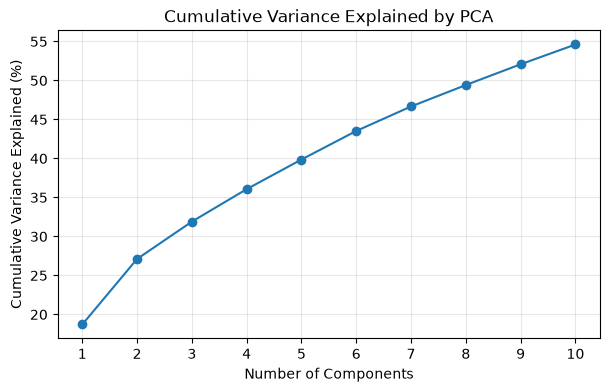

In [36]:
# PCA explained variance
plt.figure(figsize=(7, 4))
plt.plot(range(1, N_COMPONENTS + 1),
         pca.explained_variance_ratio_.cumsum() * 100, marker="o")
plt.title("Cumulative Variance Explained by PCA")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained (%)")
plt.xticks(range(1, N_COMPONENTS + 1))
plt.grid(alpha=0.3)
plt.show()

### 3.3 Choose a Modeling Sample

Our cleaned data has over 60,000 mushrooms. Agglomerative clustering is especially expensive on large datasets, so we use one random sample of up to **4,000 mushrooms** for choosing parameters and comparing all three methods. 

K-Means can scale to the full dataset, so we will fit the selected K-Means configuration on **all** mushrooms later as a deployment example.

In [37]:
# Same sample for all three methods
SAMPLE_SIZE = min(4000, len(df))
sample_idx = df.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).index.to_numpy()
X_sample = X_pca[sample_idx]
sample_df = df.iloc[sample_idx].reset_index(drop=True)

print("Clustering sample:", X_sample.shape)
print("Full data:", X_pca.shape)

# The known labels are kept separately for later interpretation
print("\nEdibility proportions (full dataset):")
print(df["class"].value_counts(normalize=True).round(3))
print("\nEdibility proportions (random sample):")
print(sample_df["class"].value_counts(normalize=True).round(3))

Clustering sample: (4000, 10)
Full data: (60923, 10)

Edibility proportions (full dataset):
class
poisonous    0.554
edible       0.446
Name: proportion, dtype: float64

Edibility proportions (random sample):
class
poisonous    0.564
edible       0.436
Name: proportion, dtype: float64


## 4. Modeling and Evaluation (CRISP-DM)

We are using the following three clustering methods:

- **K-Means:** Puts mushrooms into a chosen number of groups based on distance from cluster centers.
- **Agglomerative Clustering:** Starts with individual observations and combines nearby groups. We will compare Ward, complete, and average linkage.
- **DBSCAN:** Finds groups of nearby observations. It uses `eps` and `min_samples` instead of requiring a fixed number of clusters. It can also mark observations as noise (`-1`).

### 4.1 How We Will Evaluate the Clusters

The main measure used to choose settings is the **silhouette score**. It tells us whether points are closer to their own cluster than to other clusters. A larger score generally means better separation.

We will look at both **Euclidean** and **cosine** silhouette scores for K-Means. Euclidean silhouette will be our common score for choosing settings and comparing all three methods. We will also report the number and sizes of the clusters, along with DBSCAN's noise percentage.

Once the models are selected, we will use the **external validity measures** (homogeneity, completeness, V-measure, ARI, and AMI) to compare the clusters with the mushroom's known edibility label. These scores are for interpretation **after modeling**, not for choosing the models.

In [38]:
# Silhouette score is only defined when there are at least two clusters.
# We use a random sample for scoring so the calculations do not take too long.
def get_silhouette(data, labels, distance="euclidean"):
    if len(np.unique(labels)) < 2:
        return np.nan
    try:
        return metrics.silhouette_score(
            data, labels, metric=distance,
            sample_size=min(1000, len(data)), random_state=RANDOM_STATE
        )
    except ValueError:
        return np.nan

### 4.2 K-Means

We will use `KMeans`, `fit()`, and `labels_` to assign observations to groups. We will also test `k` values from 2 through 8. We will plot silhouette scores against the number of clusters.

We choose `k` from the highest **Euclidean** silhouette score. Cosine silhouette is included to see whether using a different way to measure distance changes the overall pattern.

In [39]:
# K-Means: compare different numbers of clusters
kmeans_rows = []
kmeans_labels = {}

for k in range(2, 9):
    model = KMeans(n_clusters=k, init="k-means++", n_init=10,
                   random_state=RANDOM_STATE)
    labels = model.fit_predict(X_sample)
    kmeans_labels[k] = labels

    kmeans_rows.append({
        "k": k,
        "Silhouette (Euclidean)": get_silhouette(X_sample, labels),
        "Silhouette (Cosine)": get_silhouette(X_sample, labels, "cosine")
    })

kmeans_results = pd.DataFrame(kmeans_rows)
display(kmeans_results.round(3))

,k,Silhouette (Euclidean),Silhouette (Cosine)
0,2,0.227,0.283
1,3,0.213,0.257
2,4,0.143,0.174
3,5,0.144,0.160
4,6,0.142,0.136
5,7,0.156,0.101
6,8,0.156,0.123


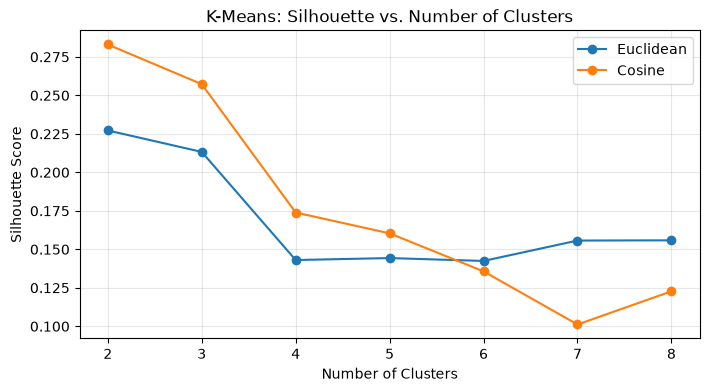

Selected K-Means k: 2


In [ ]:
# Plot the two silhouette scores
plt.figure(figsize=(8, 4))
plt.plot(kmeans_results["k"], kmeans_results["Silhouette (Euclidean)"],
         marker="o", label="Euclidean")
plt.plot(kmeans_results["k"], kmeans_results["Silhouette (Cosine)"],
         marker="o", label="Cosine")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means: Silhouette vs. Number of Clusters")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_k = int(kmeans_results.loc[
    kmeans_results["Silhouette (Euclidean)"].idxmax(), "k"
])
best_kmeans_labels = kmeans_labels[best_k]
print("Selected K-Means k:", best_k)

`k` = 2 gives us both the highest Euclidean and Cosine Silhouette scores. After `k` = 3, the graphs shows a strong decline in both Silhouette scores.

### 4.3 Agglomerative (Hierarchical) Clustering

As with K-Means, we will use the Euclidean silhouette score to choose a setting. This lets us compare Agglomerative Clustering with the other methods using the same measure.

In [41]:
# Agglomerative: try different linkage methods and cluster counts
agg_rows = []
agg_labels = {}

for link in ["ward", "complete", "average"]:
    for k in range(2, 7):
        model = AgglomerativeClustering(n_clusters=k, linkage=link)
        labels = model.fit_predict(X_sample)
        agg_labels[(link, k)] = labels
        agg_rows.append({
            "Linkage": link,
            "k": k,
            "Silhouette (Euclidean)": get_silhouette(X_sample, labels)
        })

agg_results = pd.DataFrame(agg_rows)
display(agg_results.round(3))

,Linkage,k,Silhouette (Euclidean)
0,ward,2,0.196
1,ward,3,0.191
2,ward,4,0.113
3,ward,5,0.121
4,ward,6,0.129
5,complete,2,0.483
6,complete,3,0.437
7,complete,4,0.380
8,complete,5,0.368
9,complete,6,0.174


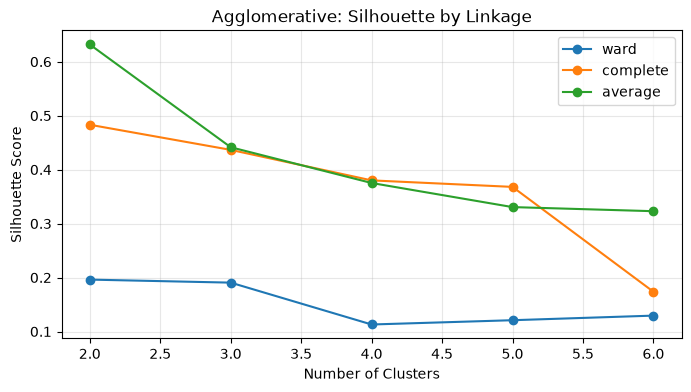

Selected linkage: average
Selected number of clusters: 2


In [42]:
# Compare the linkage methods
plt.figure(figsize=(8, 4))
for link in ["ward", "complete", "average"]:
    values = agg_results[agg_results["Linkage"] == link]
    plt.plot(values["k"], values["Silhouette (Euclidean)"],
             marker="o", label=link)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Agglomerative: Silhouette by Linkage")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_agg_row = agg_results.loc[agg_results["Silhouette (Euclidean)"].idxmax()]
best_link = best_agg_row["Linkage"]
best_agg_k = int(best_agg_row["k"])
best_agg_labels = agg_labels[(best_link, best_agg_k)]

print("Selected linkage:", best_link)
print("Selected number of clusters:", best_agg_k)

The average linkage method with a cluster count of 2 performed the best. The average linkage method outperfomred the k-means Euclidean Silhouette score by nearly 3 times (k-means: 0.227, average: 0.632). Therefore, the average linkage method produced more distinct clusters than the k-means clustering algorithm did.

### 4.4 DBSCAN

We will try several `eps` and `min_samples` settings.

- `eps` is the distance DBSCAN uses when finding neighbors.
- `min_samples` is the number of nearby observations required to form a dense region.
- `-1` is the label for observations DBSCAN considers noise.

We will first look at nearest-neighbor distances to choose a reasonable range for **this dataset**, then test several settings.

For DBSCAN, we calculate silhouette on **non-noise points** only. We always report the noise percentage with it. A high silhouette would not be very useful if DBSCAN discarded most mushrooms.

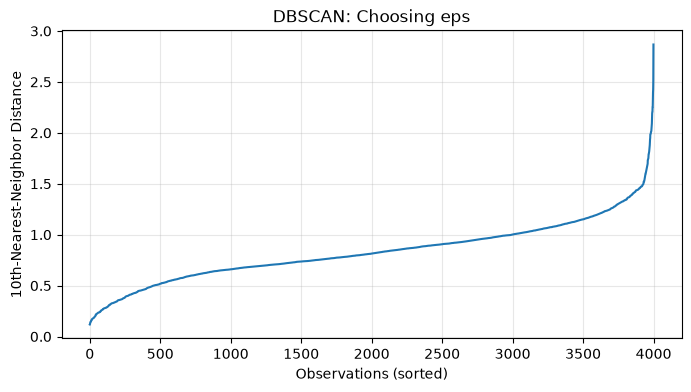

eps values to try: [0.815, 0.961, 1.115, 1.34, 1.733]


In [43]:
# Use nearest-neighbor distances to get a reasonable range for eps
neighbors = NearestNeighbors(n_neighbors=10)
neighbors.fit(X_sample)
distances, _ = neighbors.kneighbors(X_sample)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel("Observations (sorted)")
plt.ylabel("10th-Nearest-Neighbor Distance")
plt.title("DBSCAN: Choosing eps")
plt.grid(alpha=0.3)
plt.show()

eps_values = np.unique(np.round(np.quantile(k_distances,
                                            [0.50, 0.70, 0.85, 0.95, 0.99]), 3))
eps_values = [float(eps) for eps in eps_values if eps > 0]
if not eps_values:
    eps_values = [0.5]
print("eps values to try:", eps_values)

In [ ]:
# DBSCAN: compare eps and min_samples
dbscan_rows = []
dbscan_labels = {}

for eps in eps_values:
    for mpts in [5, 10, 15]:
        model = DBSCAN(eps=eps, min_samples=mpts)
        labels = model.fit_predict(X_sample)
        dbscan_labels[(eps, mpts)] = labels

        num_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = (labels == -1).mean() * 100
        data_used = X_sample[labels != -1]
        labels_used = labels[labels != -1]

        # A silhouette needs at least two non-noise clusters.
        score = get_silhouette(data_used, labels_used) if num_clusters >= 2 else np.nan

        dbscan_rows.append({
            "eps": eps,
            "min_samples": mpts,
            "Clusters": num_clusters,
            "Noise %": noise_pct,
            "Silhouette (Euclidean)": score
        })

dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.round(3))

,eps,min_samples,Clusters,Noise %,Silhouette (Euclidean)
0,0.815,5,135,9.825,0.064
1,0.815,10,93,30.450,0.142
2,0.815,15,47,55.300,0.287
3,0.961,5,78,3.525,-0.070
4,0.961,10,60,13.725,-0.034
5,0.961,15,35,31.250,-0.067
6,1.115,5,40,1.000,-0.043
7,1.115,10,35,5.350,-0.033
8,1.115,15,27,15.600,-0.028
9,1.340,5,16,0.425,-0.043


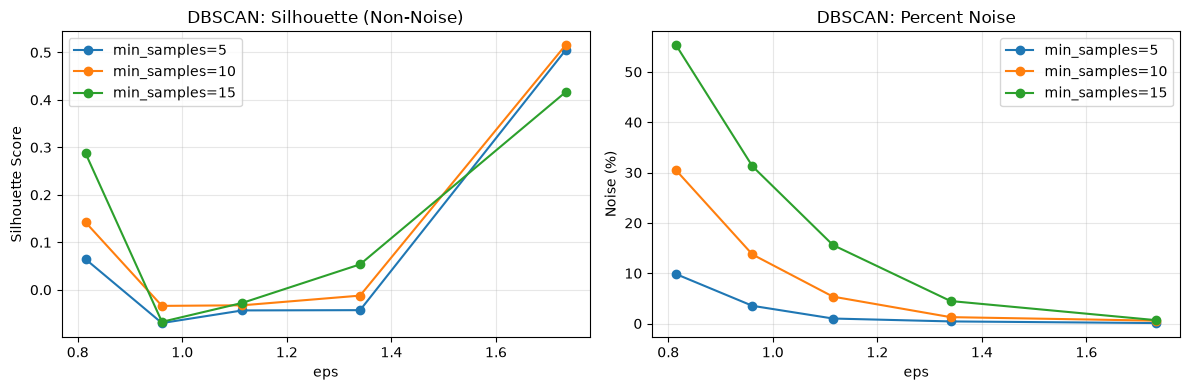

Selected eps: 1.733
Selected min_samples: 10
Clusters found: 3
Percent noise: 0.6


In [45]:
# Compare DBSCAN silhouette and the percentage labeled noise
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mpts in [5, 10, 15]:
    values = dbscan_results[dbscan_results["min_samples"] == mpts]
    axes[0].plot(values["eps"], values["Silhouette (Euclidean)"],
                 marker="o", label=f"min_samples={mpts}")
    axes[1].plot(values["eps"], values["Noise %"],
                 marker="o", label=f"min_samples={mpts}")

axes[0].set_title("DBSCAN: Silhouette (Non-Noise)")
axes[0].set_ylabel("Silhouette Score")
axes[1].set_title("DBSCAN: Percent Noise")
axes[1].set_ylabel("Noise (%)")
for ax in axes:
    ax.set_xlabel("eps")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Prefer at least two clusters and no more than 50% noise.
candidates = dbscan_results[
    (dbscan_results["Clusters"] >= 2) &
    (dbscan_results["Noise %"] <= 50) &
    (dbscan_results["Silhouette (Euclidean)"].notna())
]
if candidates.empty:
    candidates = dbscan_results[
        (dbscan_results["Clusters"] >= 2) &
        (dbscan_results["Silhouette (Euclidean)"].notna())
    ]

if candidates.empty:
    # If DBSCAN finds no usable multi-cluster result, show the least-noisy case.
    best_dbscan_row = dbscan_results.loc[dbscan_results["Noise %"].idxmin()]
else:
    best_dbscan_row = candidates.loc[candidates["Silhouette (Euclidean)"].idxmax()]

best_eps = float(best_dbscan_row["eps"])
best_min_samples = int(best_dbscan_row["min_samples"])
best_dbscan_labels = dbscan_labels[(best_eps, best_min_samples)]

print("Selected eps:", best_eps)
print("Selected min_samples:", best_min_samples)
print("Clusters found:", int(best_dbscan_row["Clusters"]))
print("Percent noise:", round(float(best_dbscan_row["Noise %"]), 1))

Generally when `eps` & `min_samples` increaess, the number of clusters appears to decrease. However, it's worth noting `eps` appears to have more of an impact in this area. When `min_samples` increase, so does noise percentage. Yet when `eps` increases, the noise percentage generally decreases.

## 5. Compare the Models and Interpret the Clusters

### 5.1 Compare Silhouette Scores

We compare the selected settings using the same **Euclidean silhouette** measure from Lecture 10. DBSCAN's silhouette is calculated on the observations it did not label as noise, so its noise percentage must be considered too.

We also compare cluster counts and sizes. There is no guarantee that the solution with the highest silhouette will be the most useful to someone studying mushrooms.

In [46]:
# Compare the selected clustering methods
cluster_labels = {
    "K-Means": best_kmeans_labels,
    "Agglomerative": best_agg_labels,
    "DBSCAN": best_dbscan_labels
}

comparison_rows = []
for name, labels in cluster_labels.items():
    num_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100
    data_used = X_sample[labels != -1]
    labels_used = labels[labels != -1]
    score = get_silhouette(data_used, labels_used) if num_clusters >= 2 else np.nan

    comparison_rows.append({
        "Model": name,
        "Clusters": num_clusters,
        "Silhouette (Euclidean)": score,
        "Noise %": noise_pct
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))

,Model,Clusters,Silhouette (Euclidean),Noise %
0,K-Means,2,0.227,0.000
1,Agglomerative,2,0.632,0.000
2,DBSCAN,3,0.515,0.575


### 5.2 Visualize the Clusters

Our professor uses scatterplots to show how the clustering algorithms separate the observations. We will do the same with the first two principal components. **The models were fit on 10 components**, so these pictures do not show every difference between the groups.

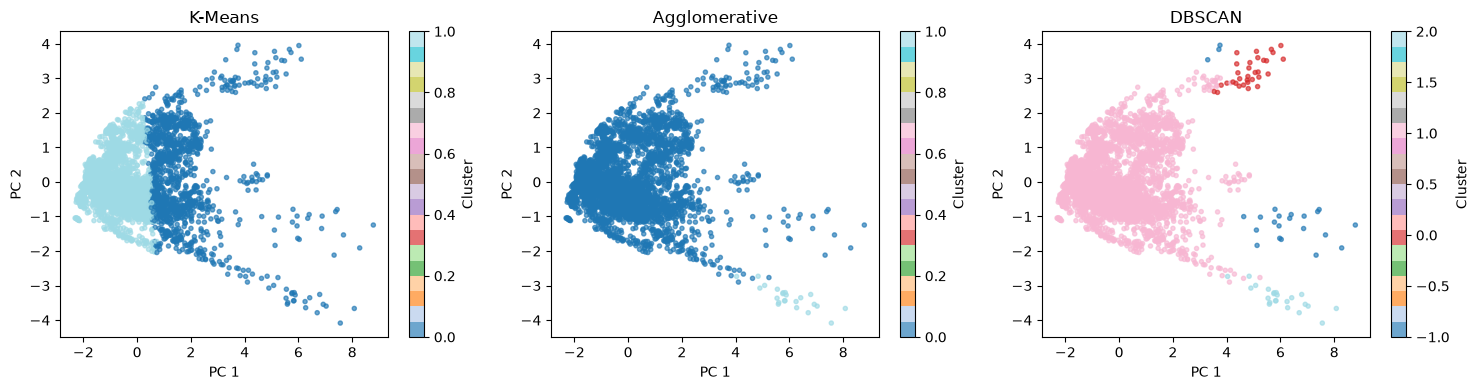

In [47]:
# Show the same PCA observations colored by each clustering method
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, labels) in zip(axes, cluster_labels.items()):
    points = ax.scatter(X_sample[:, 0], X_sample[:, 1], c=labels,
                        cmap="tab20", s=9, alpha=0.65)
    ax.set_title(name)
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    fig.colorbar(points, ax=ax, label="Cluster")
plt.tight_layout()
plt.show()

### 5.3 Cluster Sizes

A silhouette score is not enough by itself. We also want to know whether the algorithms created a few very large groups or many smaller ones. DBSCAN uses `-1` for noise.


 K-Means cluster sizes:
0    1244
1    2756

 Agglomerative cluster sizes:
0    3977
1      23

 DBSCAN cluster sizes:
-1      23
 0      32
 1    3922
 2      23


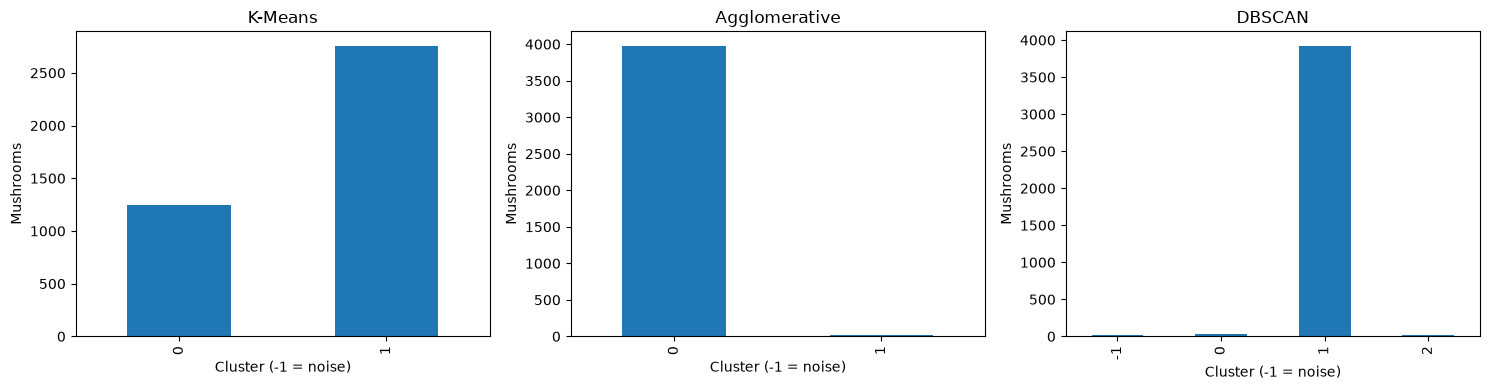

In [48]:
# Count the mushrooms in each cluster
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, labels) in zip(axes, cluster_labels.items()):
    sizes = pd.Series(labels).value_counts().sort_index()
    print("\n", name, "cluster sizes:")
    print(sizes.to_string())
    sizes.plot(kind="bar", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Cluster (-1 = noise)")
    ax.set_ylabel("Mushrooms")
plt.tight_layout()
plt.show()

### 5.4 Describe the Mushroom Groups

To understand what the clusters actually mean, we go back to the original mushroom characteristics. We compare typical cap diameter, stem height, stem width, cap shape, habitat, and gill spacing within each group.

For methods that create many clusters, we show the eight largest groups to keep the tables manageable.

In [49]:
# Look at original mushroom measurements and categories within each cluster
for name, labels in cluster_labels.items():
    profile = sample_df.copy()
    profile["Cluster"] = labels
    largest = profile["Cluster"].value_counts().head(8).index
    profile = profile[profile["Cluster"].isin(largest)]

    print("\n---", name, "---")
    print("Median measurements:")
    display(profile.groupby("Cluster")[num_original].median().round(2))

    print("Most common categories:")
    display(profile.groupby("Cluster")[["cap-shape", "habitat", "gill-spacing"]].agg(
        lambda s: s.value_counts().idxmax()
    ))


--- K-Means ---
Median measurements:


,cap-diameter,stem-height,stem-width
Cluster,,,
0,9.91,8.88,19.16
1,4.42,5.34,6.91


Most common categories:


,cap-shape,habitat,gill-spacing
Cluster,,,
0,convex,woods,Missing
1,convex,woods,close



--- Agglomerative ---
Median measurements:


,cap-diameter,stem-height,stem-width
Cluster,,,
0,5.95,6.05,10.33
1,49.34,6.44,33.52


... (2 outputs left out)


--- DBSCAN ---
Median measurements:


,cap-diameter,stem-height,stem-width
Cluster,,,
-1,17.63,17.55,68.48
0,17.54,25.30,20.20
1,5.89,6.02,10.18
2,49.34,6.44,33.52


Most common categories:


,cap-shape,habitat,gill-spacing
Cluster,,,
-1,spherical,woods,Missing
0,flat,woods,Missing
1,convex,woods,Missing
2,others,woods,Missing


### 5.5 Cluster Validity with Known Edibility Labels

In *10. Clustering Validity*, our professor compares cluster assignments with known labels using the following scores:

- **Homogeneity:** Does each cluster mostly contain one known class?
- **Completeness:** Do mushrooms from the same known class tend to stay together?
- **V-measure:** Combines homogeneity and completeness.
- **Adjusted Rand Index (ARI):** Measures agreement between the two sets of groupings, adjusted for chance.
- **Adjusted Mutual Information (AMI):** Another way to measure agreement, adjusted for chance.

**Important:** We did **not** use `class` in our clustering data or to choose the settings above. Now we can check whether the groups we found happen to line up with edible versus poisonous. We should not expect these groups to match perfectly: we are clustering physical features, not training a classifier. Also, a low score against edibility does not mean the clusters are useless for exploring mushroom shapes or habitats.

DBSCAN's `-1` noise label is treated as an additional group by these external measures, so we interpret its scores carefully.

In [50]:
# External cluster validity scores from Lecture 10
# Edibility labels are used ONLY after the clusters are formed.
validity_rows = []
true_labels = sample_df["class"]

for name, labels in cluster_labels.items():
    validity_rows.append({
        "Model": name,
        "Homogeneity": metrics.homogeneity_score(true_labels, labels),
        "Completeness": metrics.completeness_score(true_labels, labels),
        "V-measure": metrics.v_measure_score(true_labels, labels),
        "ARI": metrics.adjusted_rand_score(true_labels, labels),
        "AMI": metrics.adjusted_mutual_info_score(true_labels, labels)
    })

validity_results = pd.DataFrame(validity_rows)
display(validity_results.round(3))

# Percent edible and poisonous within each cluster
for name, labels in cluster_labels.items():
    print("\n---", name, "---")
    table = pd.crosstab(pd.Series(labels, name="Cluster"), true_labels,
                        normalize="index") * 100
    display(table.round(1))

,Model,Homogeneity,Completeness,V-measure,ARI,AMI
0,K-Means,0.008,0.009,0.009,0.019,0.008
1,Agglomerative,0.007,0.136,0.013,0.004,0.013
2,DBSCAN,0.024,0.140,0.041,0.013,0.040



--- K-Means ---


class,edible,poisonous
Cluster,,
0,51.4,48.6
1,40.0,60.0



--- Agglomerative ---


class,edible,poisonous
Cluster,,
0,43.2,56.8
1,100.0,0.0



--- DBSCAN ---


class,edible,poisonous
Cluster,,
-1,100.0,0.0
0,100.0,0.0
1,42.4,57.6
2,100.0,0.0


**After running:** Complete these observations using your actual results:

1. Which method had the highest Euclidean silhouette score? Was its noise percentage reasonable?
2. What linkage and cluster count worked best for Agglomerative Clustering?
3. How did DBSCAN compare with the other methods? Did it label many mushrooms as noise?
4. Which physical traits seem to distinguish the clusters?
5. Do the clusters line up with edible/poisonous labels based on homogeneity, completeness, V-measure, ARI, and AMI? If not, what might explain that?

The external scores describe **agreement with the edibility label**, not whether the clustering is objectively good for every possible research question. We should judge both the internal scores and the actual cluster descriptions.

## 6. Deployment (CRISP-DM)

Clustering could be useful as an exploratory tool for mushroom researchers or educators. For example, a user could enter physical measurements and categories and see which general group a mushroom resembles. Researchers could then look for patterns in those groups or study unusual observations.

**Limits:** We clustered on a random sample for our main comparison, and our feature representation uses Euclidean distance on scaled and one-hot-encoded data. Results could change if we used different feature weights, another region, or another set of mushrooms. Most importantly, cluster membership is **not** evidence that a mushroom is safe to eat.

**Possible deployment approach:** K-Means is the most straightforward method to apply to new mushrooms because it has a `predict` method. If its clusters are useful, we could refit it using all cleaned mushrooms and save the preprocessing, PCA, and K-Means steps together in a pipeline. Agglomerative Clustering and DBSCAN do not have a comparable built-in `predict` method in scikit-learn.

**How we would measure value:** Ask researchers whether cluster descriptions help identify patterns, check whether groups remain stable with newly collected data, and track changes in cluster sizes or feature distributions. We would also look for meaningful differences across regions or species if those labels become available.

**Additional data:** Confirmed mushroom species, location, expert annotations, weather, collection conditions, and more representative samples from new habitats. The model should be reviewed when these data change and retrained when the clusters no longer describe new observations well.

In [51]:
# Example: fit a final K-Means pipeline on the entire dataset
# This is a deployment example, not a safety or edibility prediction model.
final_kmeans = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ])),
    ("pca", PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)),
    ("model", KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE))
])

final_kmeans.fit(X)
print("Final K-Means trained on", len(X), "mushrooms")
print("Example cluster assignments:", final_kmeans.predict(X.head(5)))

Final K-Means trained on 60923 mushrooms
Example cluster assignments: [0 0 0 0 0]


## 7. Exceptional Work: Check K-Means Stability

One additional check is to fit K-Means several times with different random seeds. We compare those cluster assignments using ARI. Here, ARI compares **one run of K-Means to another**, not to the edible/poisonous labels.

If the values are close to 1, K-Means is finding similar groups across initializations. If they are low, the exact cluster assignments depend more strongly on how the model starts.

In [52]:
# Compare K-Means solutions with different random seeds
seeds = [7, 21, 42]
stability_labels = {}
for seed in seeds:
    model = KMeans(n_clusters=best_k, n_init=10, random_state=seed)
    stability_labels[seed] = model.fit_predict(X_sample)

stability_rows = []
for i, first_seed in enumerate(seeds):
    for second_seed in seeds[i + 1:]:
        stability_rows.append({
            "Seed 1": first_seed,
            "Seed 2": second_seed,
            "ARI Between Runs": metrics.adjusted_rand_score(
                stability_labels[first_seed], stability_labels[second_seed]
            )
        })

display(pd.DataFrame(stability_rows).round(3))

,Seed 1,Seed 2,ARI Between Runs
0,7,21,1.0
1,7,42,1.0
2,21,42,1.0


**After running:** Comment on whether the K-Means results were stable across the different seeds. High stability supports reproducibility, but it does not prove that the clusters are scientifically meaningful.

## 8. Final Conclusions

Our goal was to find meaningful groups in the mushroom dataset without using the known classification labels. We compared K-Means, Agglomerative Clustering, and DBSCAN using a common data representation and the same sampled observations. We evaluated the results using internal clustering scores, cluster sizes, visualizations, and the original mushroom characteristics.

**Complete this paragraph after running the notebook:** State which method you would choose, its selected parameters and key scores, the most interesting differences between its groups, and whether those groups showed any relationship to edibility. Also describe one limitation of the approach and how you would improve it with more data.

**Overall takeaway:** Clustering is useful for exploring patterns, but our results need external validation before any real-world use. It should not be used to determine mushroom safety.

### Reproducibility Notes

- Run this notebook from top to bottom in Python 3.
- Libraries: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `ucimlrepo`, and `certifi`.
- The dataset is loaded through `fetch_ucirepo(id=848)`, so an internet connection is needed if it is not already cached.
- Cleaning functions are included in the notebook, as in Lab 2.
- The modeling comparison uses a reproducible sample of up to 4,000 mushrooms. To make the notebook faster, you can reduce `SAMPLE_SIZE` in Section 3.3, then rerun every section that follows and note the change.
- The scores in Sections 4 and 5 come from the professor's *09. Clustering and Discretization* and *10. Clustering Validity* notebooks. The stability check also uses ARI, which was covered in Lecture 10.
- Describe your findings in the **After running** sections before submitting. Do not claim results you have not observed.

**Data source:** [UCI Secondary Mushroom Dataset](https://archive.ics.uci.edu/dataset/848/secondary+mushroom+dataset).
